# Bahdanau 注意力
引入注意力机制的 Seq2Seq 模型。

- 原始 Seq2Seq 模型：Encoder-Decoder 架构，Encoder 把源句编码成隐藏状态，Decoder 根据这个隐藏状态生成目标句。



  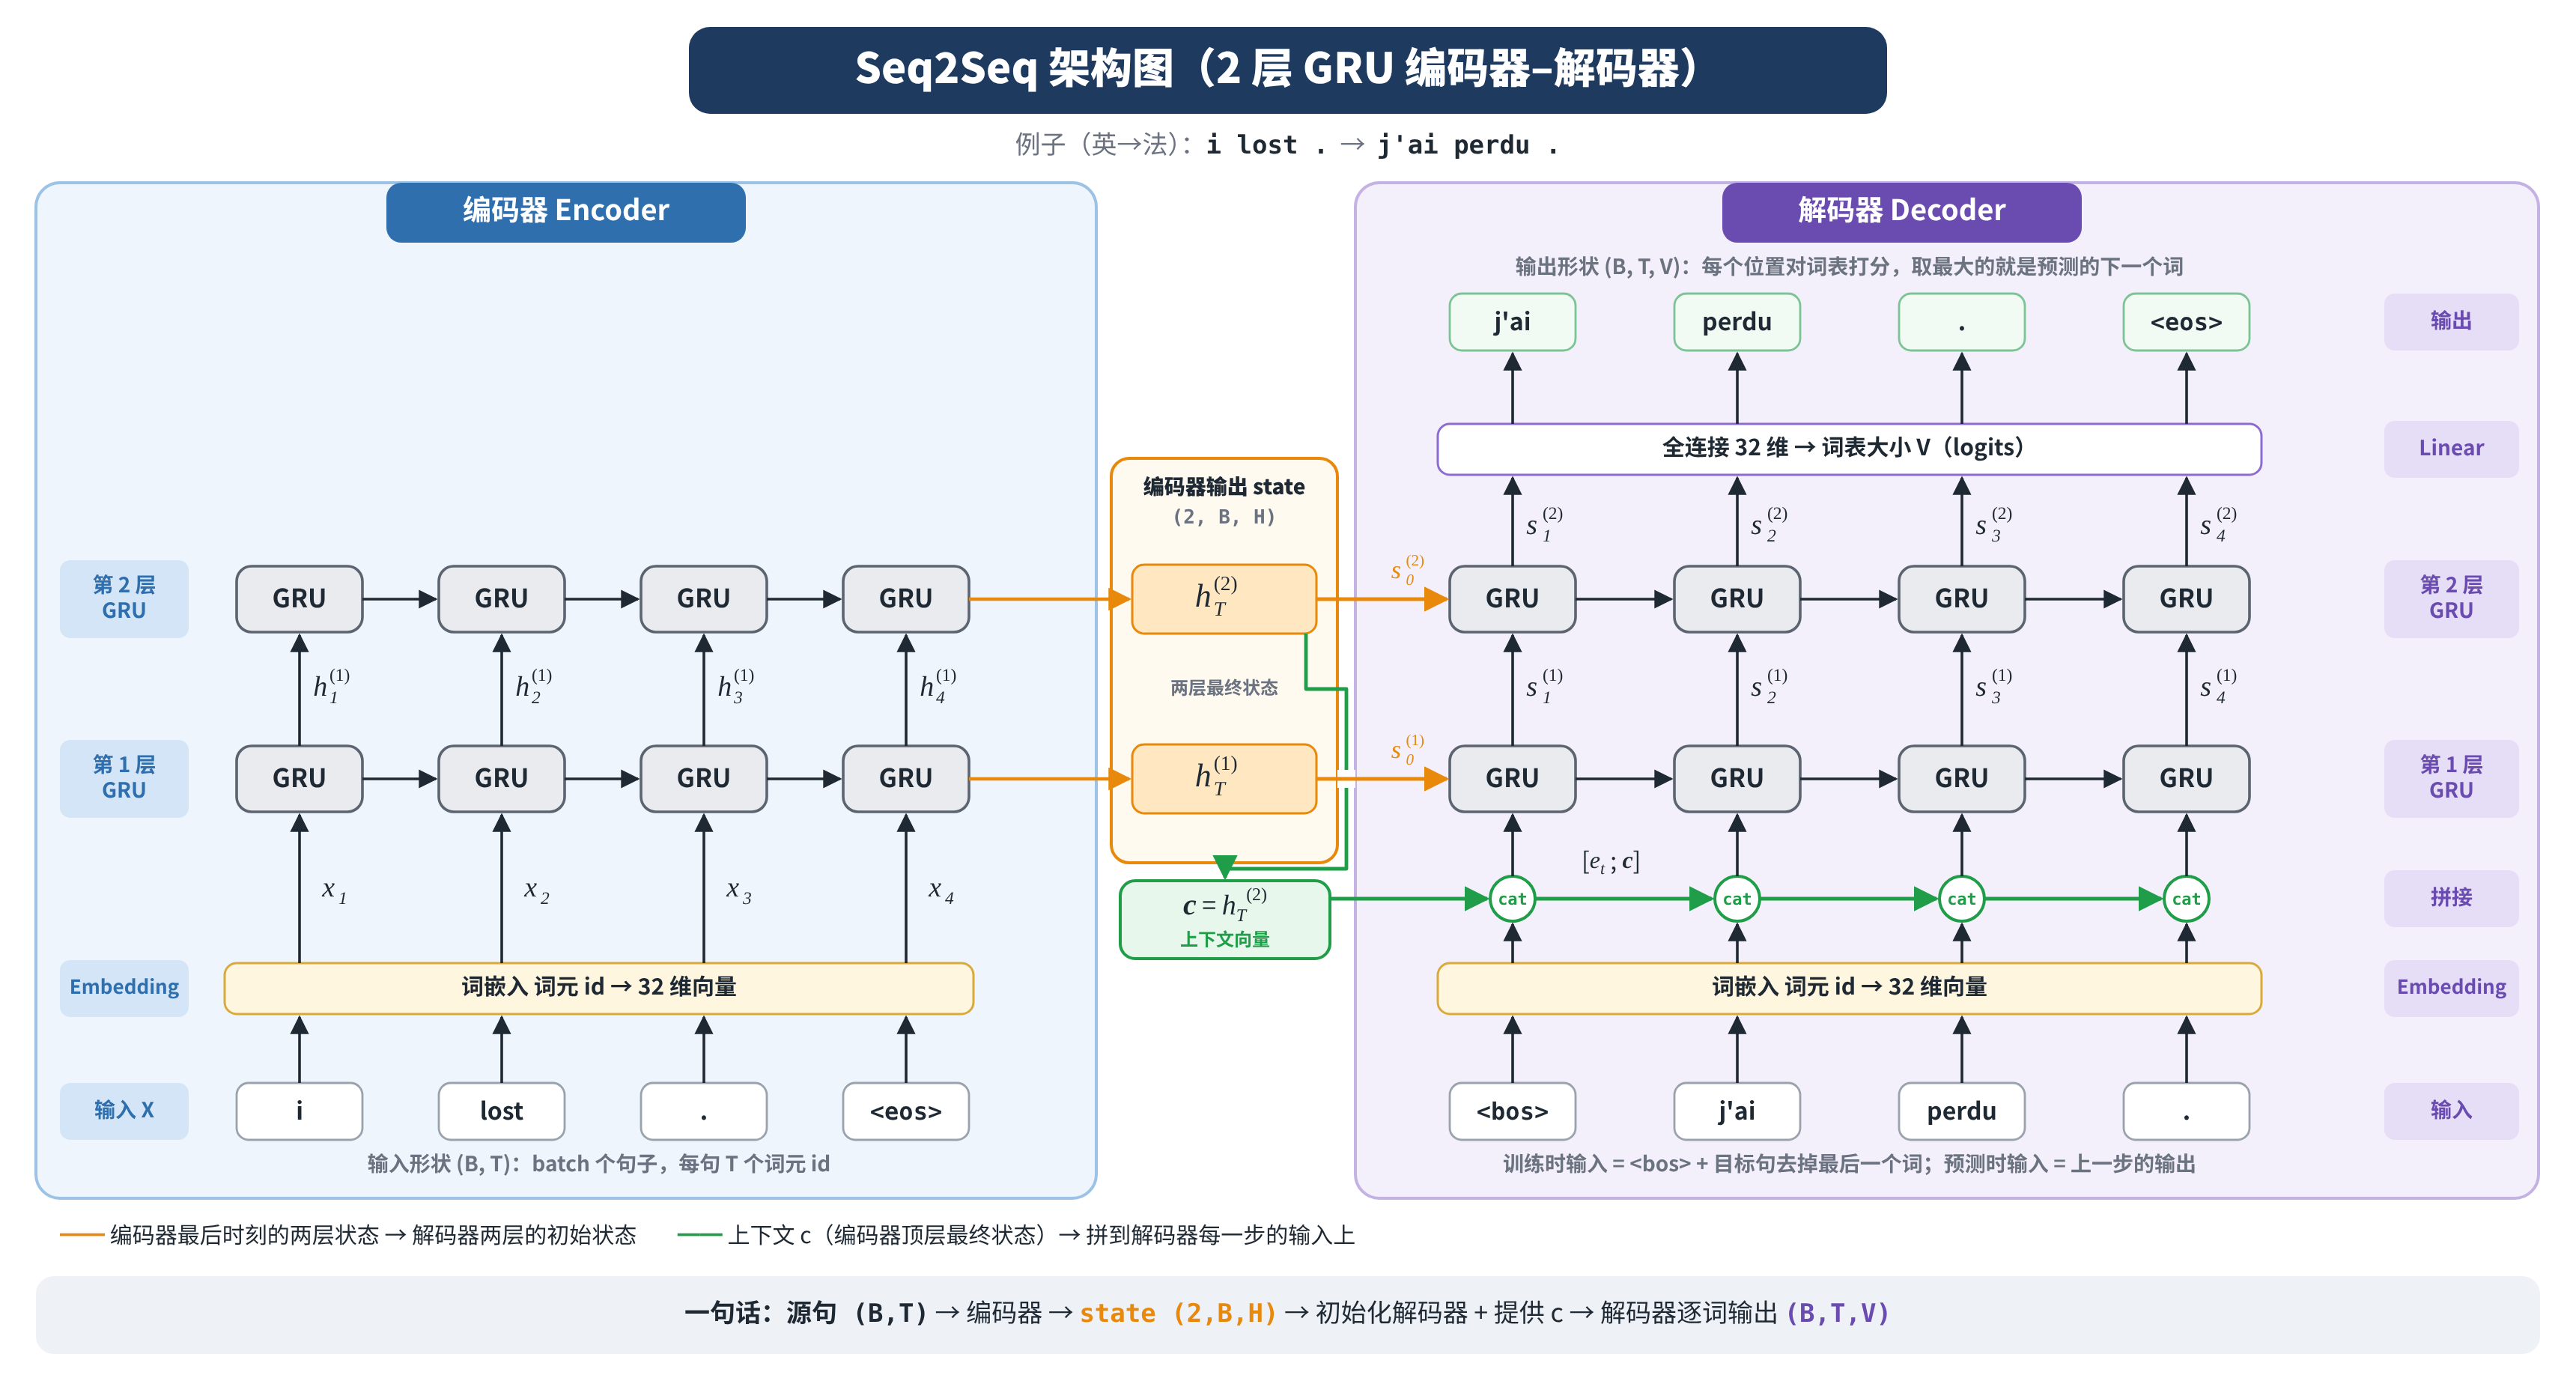

- 引入注意力机制的 Seq2Seq 模型。

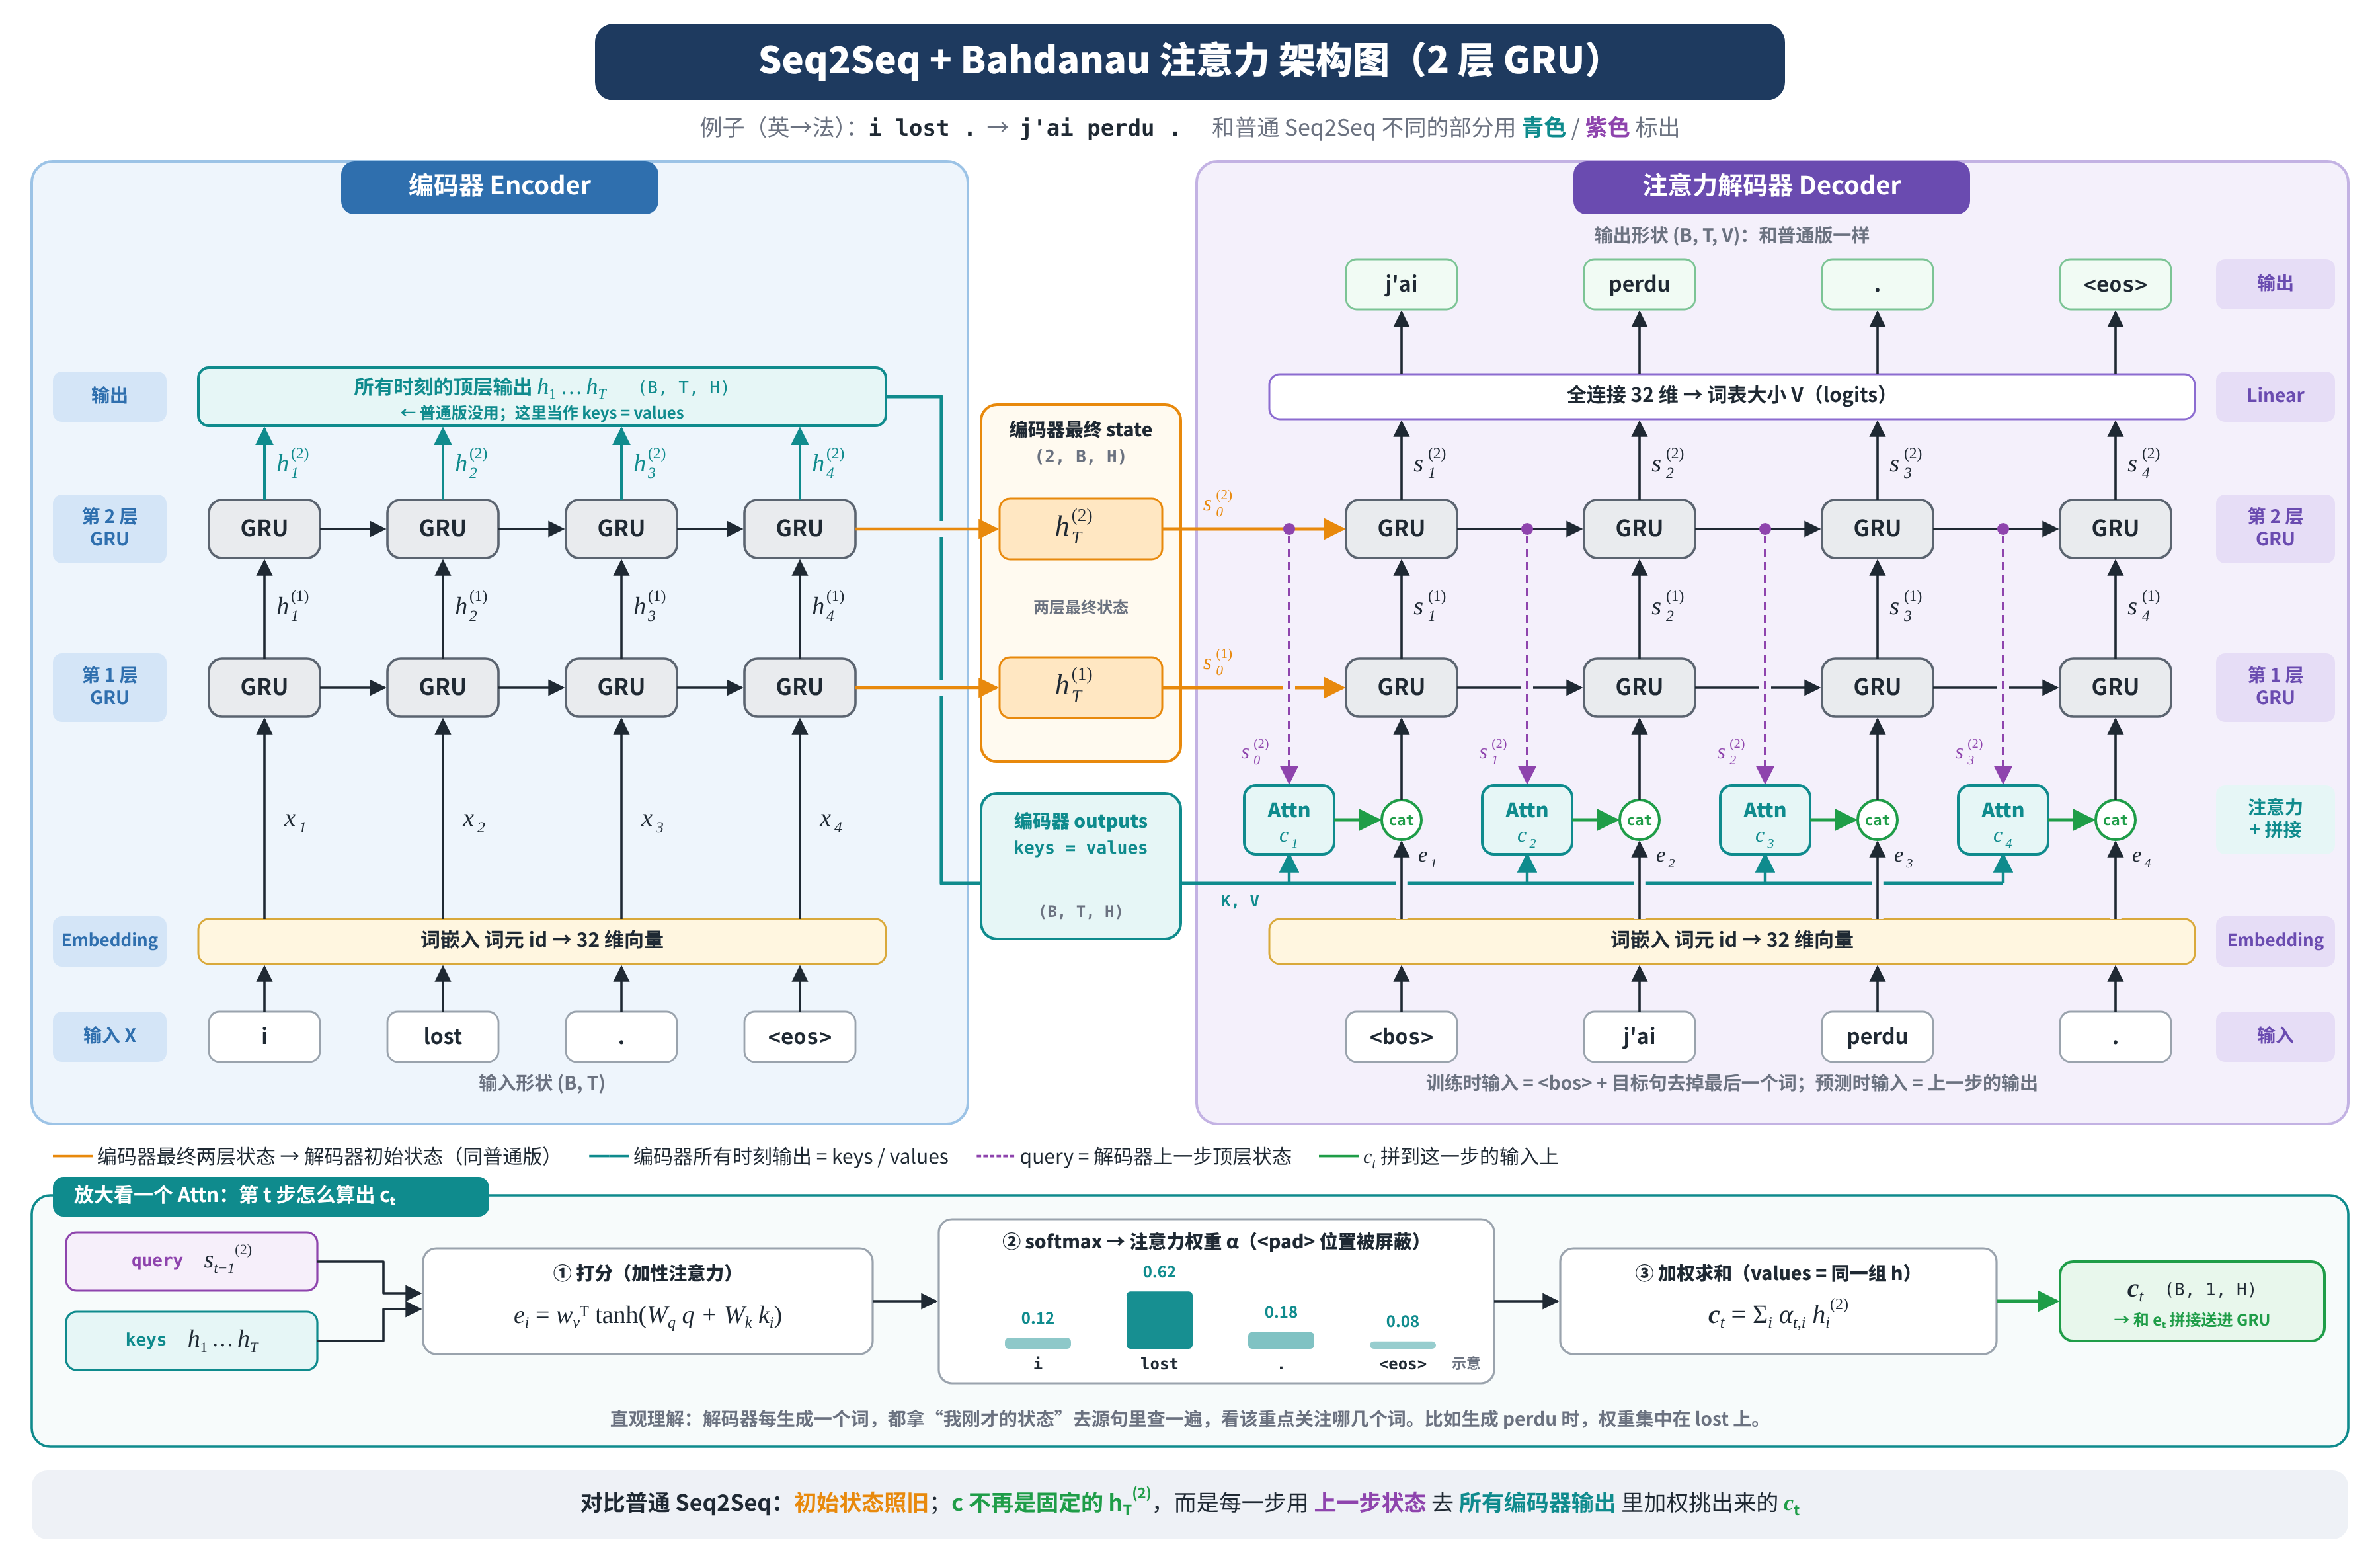

## 10.4 Bahdanau 注意力（Bahdanau Attention）

### 1. 工作原理

传统 Seq2Seq 使用 Encoder 最后一个时间步的隐藏状态作为固定上下文向量 $c$，Decoder 在每个时间步都使用相同的 $c$，难以针对当前预测任务关注源句中的不同位置。

**Bahdanau 注意力的核心改进：Decoder 在每个时间步，根据上一个时间步的隐藏状态，动态计算对 Encoder 各位置的注意力权重，从而生成不同的上下文向量 $c_t$。**

Q、K、V 的来源：

- **Query（Q）**：Decoder 上一个时间步的顶层隐藏状态 $s_{t-1}$，表示当前需要什么信息。
- **Key（K）**：Encoder 所有时间步的顶层隐藏状态 $h_1,h_2,\ldots,h_T$，用于计算匹配分数。
- **Value（V）**：同样是 Encoder 所有时间步的顶层隐藏状态，用于加权求和。

### 2. 计算过程

**第一步：通过加性注意力计算 Q 与各 Key 的匹配分数。**

$$
e_{t,i}=w_v^\top\tanh(W_qs_{t-1}+W_kh_i)
$$

**第二步：Softmax 归一化，得到注意力权重。**

$$
\alpha_{t,i}=\frac{\exp(e_{t,i})}{\sum_{j=1}^{T}\exp(e_{t,j})}
$$

**第三步：对 Encoder 的所有 Value 加权求和，生成当前上下文向量。**

$$
\boxed{c_t=\sum_{i=1}^{T}\alpha_{t,i}h_i}
$$

**第四步：将 $c_t$ 与当前输入 Token 的 Embedding 拼接，送入 Decoder GRU，更新隐藏状态并预测当前词元。**

$$
z_t=[Embedding(y_{t-1});c_t]
$$

$$
s_t=GRU(z_t,s_{t-1})
$$

这里使用单层 GRU 简化表示，双层 GRU 则逐层更新隐藏状态。预测阶段的 $y_{t-1}$ 来自上一步预测，教师强制训练时使用真实的上一词元。

### 3. 具体例子

假设翻译：`I love you` → `我 爱 你`。

Encoder 生成三个隐藏状态 $[h_1,h_2,h_3]$，作为固定的 K、V，并用最终隐藏状态初始化 Decoder。

**预测“我”时：** Query 为 $s_0$，假设注意力权重为：

$$
\alpha_1=[0.7,0.2,0.1]
$$

$$
c_1=0.7h_1+0.2h_2+0.1h_3
$$

此时主要关注 `I`，将 $c_1$ 与 `<bos>` 的 Embedding 拼接，输入 GRU，更新得到 $s_1$ 并预测“我”。

**预测“爱”时：** Query 更新为 $s_1$，重新计算注意力，假设：

$$
\alpha_2=[0.1,0.8,0.1]
$$

$$
c_2=0.1h_1+0.8h_2+0.1h_3
$$

此时主要关注 `love`，将 $c_2$ 与上一词元“我”的 Embedding 拼接，更新得到 $s_2$ 并预测“爱”。

以上权重为示意，实际注意力不一定严格一词对应一词。

### 4. 核心总结

**普通 Seq2Seq：** Decoder 使用固定上下文向量 $c$，主要依赖 Encoder 最终隐藏状态传递源句信息。

**Bahdanau Seq2Seq：** Decoder 每一步使用不同的 Query，对 Encoder 全部隐藏状态重新计算注意力，生成动态上下文向量 $c_t$。

**关键区别：Encoder 的 K、V 在解码过程中保持不变，Decoder 的 Query 随隐藏状态不断更新，因此注意力权重和上下文向量也会动态变化。**

注意：Bahdanau Attention 并没有替换 GRU，而是在 Decoder 中加入加性注意力，使其能够动态获取 Encoder 不同位置的信息。

In [5]:
import torch
from torch import nn
from d2l import torch as d2l

In [6]:
#@save
class AttentionDecoder(d2l.Decoder):
    """带有注意力机制解码器的基本接口"""
    def __init__(self, **kwargs):
        super(AttentionDecoder, self).__init__(**kwargs)

    @property
    def attention_weights(self):
        raise NotImplementedError

In [8]:
class Seq2SeqAttentionDecoder(d2l.Decoder):
    """带有注意力机制的解码器"""
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers, dropout=0, **kwargs):
        super(Seq2SeqAttentionDecoder, self).__init__(**kwargs)
        self.attention = d2l.AdditiveAttention(num_hiddens, num_hiddens, num_hiddens, dropout)
        # 嵌入层，每个 token 用一个embed_size维的向量表示 
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.rnn = nn.GRU(embed_size + num_hiddens, num_hiddens, num_layers, dropout=dropout)
        self.dense = nn.Linear(num_hiddens, vocab_size) # 全连接层

    def init_state(self, enc_outputs, enc_valid_lens, *args):
        # outputs的形状为(batch_size，num_steps，num_hiddens).
        # hidden_state的形状为(num_layers，batch_size，num_hiddens)
        outputs, hidden_state = enc_outputs
        return (outputs.permute(1, 0, 2), hidden_state, enc_valid_lens)

    def forward(self, X, state):
        # enc_outputs的形状为(batch_size,num_steps,num_hiddens).
        # hidden_state的形状为(num_layers,batch_size,num_hiddens)
        enc_outputs, hidden_state, enc_valid_lens = state
        # 输出X的形状为(num_steps,batch_size,embed_size)
        X = self.embedding(X).permute(1, 0, 2) 
        outputs, self._attention_weights = [], []
        for x in X: # 按时间步循环
            # query的形状为(batch_size,1,num_hiddens)
            query = torch.unsqueeze(hidden_state[-1], dim=1) # hidden_state[-1] 取出的是每次第二层 rnn 的输出
            # context的形状为(batch_size,1,num_hiddens)
            context = self.attention(query, enc_outputs, enc_outputs, enc_valid_lens)
            # 在特征维度上连结
            x = torch.cat((context, torch.unsqueeze(x, dim=1)), dim=-1)
            # 将x变形为(1,batch_size,embed_size+num_hiddens)
            out, hidden_state = self.rnn(x.permute(1, 0, 2), hidden_state)
            outputs.append(out)
            self._attention_weights.append(self.attention.attention_weights)
        # 全连接层变换后，outputs的形状为
        # (num_steps,batch_size,vocab_size)
        outputs = self.dense(torch.cat(outputs, dim=0))
        return outputs.permute(1, 0, 2), [enc_outputs, hidden_state, enc_valid_lens]

    @property
    def attention_weights(self):
        return self._attention_weights



## 一、核心原理与模型结构

普通 Seq2Seq 主要依赖 Encoder 的最终隐藏状态向 Decoder 传递源句信息，长序列容易出现信息丢失。Bahdanau Attention 在此基础上引入动态上下文向量，使 Decoder **每生成一个目标词，都能重新关注 Encoder 不同时间步的信息**。

`Seq2SeqAttentionDecoder` 继承 `AttentionDecoder`，主要包含四个模块：

| 模块 | 作用 |
|---|---|
| Embedding | 将目标 Token ID 转换为词嵌入向量 |
| AdditiveAttention | 根据 Query、Key、Value 计算当前 Context |
| GRU | 融合 Context、当前输入词及历史隐藏状态 |
| Linear（Dense） | 将 GRU 输出映射为目标词表的预测得分 |

设 Embedding 维度为 $E$，GRU 隐藏维度为 $H$，目标词表大小为 $V$。由于 GRU 接收 Context 与 Embedding 的拼接结果，其输入维度为 $H+E$，输出维度为 $H$，最后通过 Linear 映射到 $V$。

**与普通 Seq2Seq 的关键区别：Decoder 不再只使用固定的上下文信息，而是在每个时间步通过 Attention 动态生成 Context。**

## 二、Decoder 状态初始化：init_state()

Encoder 完成编码后返回两部分：

1. `outputs`：Encoder 顶层 GRU 在所有时间步的输出，用于 Attention 的 Key 和 Value。
2. `hidden_state`：Encoder 各层 GRU 的最终隐藏状态，用于初始化 Decoder 的对应 GRU 层。

假设单向 GRU 的层数为 $L$，Batch Size 为 $B$，源句长度为 $T_s$，隐藏维度为 $H$。

| 变量 | Shape | 用途 |
|---|---|---|
| `outputs` | $(T_s,B,H)$ | Encoder 所有时间步的顶层输出 |
| `hidden_state` | $(L,B,H)$ | Encoder 各层最终隐藏状态 |
| `enc_valid_lens` | $(B,)$ | 每条源句的有效长度 |

`init_state()` 将 `outputs` 调整为 $(B,T_s,H)$，以满足 Attention 的输入格式，同时保留另外两个变量。

最终 Decoder 状态为：

$$
state=(enc\_outputs,\ hidden\_state,\ enc\_valid\_lens)
$$

其中：

- `enc_outputs`：作为每一步 Attention 的 Key、Value，解码过程中保持不变。
- `hidden_state`：初始化 Decoder 的 GRU，并随着解码逐步更新。
- `enc_valid_lens`：用于 Masked Softmax，避免对 `<pad>` 分配注意力权重。

对于两层 GRU，初始状态满足：

$$
s_0^{(1)}=h_{T_s}^{(1)},\qquad s_0^{(2)}=h_{T_s}^{(2)}
$$

即 Encoder 各层的最终隐藏状态分别初始化 Decoder 对应层。

## 三、Decoder 前向传播：forward()

### 1. 目标序列 Embedding

假设 Decoder 输入 $X$ 包含 $B$ 条目标序列，每条长度为 $T_t$。

首先将 Token ID 转换为 $E$ 维词向量，再交换时间维和 Batch 维：

$$
(B,T_t)\rightarrow(B,T_t,E)\rightarrow(T_t,B,E)
$$

随后沿时间维遍历，每次处理整个 Batch 在当前时间步的词嵌入：

$$
x_t:(B,E)
$$

**大写 `X` 表示完整目标输入序列，小写 `x` 表示当前时间步整个 Batch 的输入词向量。**

### 2. 生成 Query

每个时间步使用 Decoder **上一时间步的顶层 GRU 隐藏状态**作为 Query：

$$
q_t=s_{t-1}^{(L)}
$$

对应 Shape：

$$
(L,B,H)\xrightarrow{\text{取最后一层}}(B,H)\xrightarrow{\text{unsqueeze}}(B,1,H)
$$

这里 `hidden_state[-1]` 取的是最后一层 GRU，而不是最后一个时间步。

需要区分：

- 第一次 Attention：Query 来自 Encoder 最终顶层隐藏状态，即 $s_0^{(L)}=h_{T_s}^{(L)}$。
- 后续 Attention：Query 来自 Decoder 上一个时间步更新后的顶层隐藏状态。

因此 Query 会随着解码过程不断变化，并非始终使用 Encoder 的最终隐藏状态。

### 3. 计算 Attention 与 Context

Bahdanau Attention 使用加性注意力：

$$
e_{t,i}=\mathbf{v}_a^\top\tanh(W_q q_t+W_k k_i)
$$

$$
\alpha_{t,i}=\operatorname{softmax}_i(e_{t,i})
$$

$$
\boxed{c_t=\sum_{i=1}^{T_s}\alpha_{t,i}v_i}
$$

其中：

- Query：Decoder 上一时间步的顶层隐藏状态，Shape 为 $(B,1,H)$。
- Key：Encoder 所有时间步的顶层输出，Shape 为 $(B,T_s,H)$。
- Value：与 Key 相同，Shape 为 $(B,T_s,H)$。
- $\alpha_{t,i}$：第 $t$ 个解码时间步对源句第 $i$ 个位置的注意力权重。

这里 Key 和 Value 使用同一个 `enc_outputs`，但承担不同作用：**Query 与 Key 计算关注程度，注意力权重对 Value 加权求和，生成 Context。**

Context 的 Shape 为：

$$
c_t:(B,1,H)
$$

例如翻译「我爱你 → I love you」，当 Decoder 准备生成 `love` 时，假设对「我、爱、你」的注意力权重为 $[0.1,0.8,0.1]$，则：

$$
c_t=0.1h_1+0.8h_2+0.1h_3
$$

模型重点利用「爱」对应的 Encoder 隐藏状态，但同时保留其他位置的上下文信息。实际权重由模型训练学习得到。

### 4. 拼接 Context 与 Embedding，更新 GRU

将当前目标输入词的 Embedding 与 Context 在特征维度拼接：

$$
u_t=[c_t;\operatorname{Embed}(y_{t-1})]
$$

Shape 变化：

$$
(B,1,H)+(B,1,E)\rightarrow(B,1,H+E)
$$

再调整为 GRU 默认的输入格式：

$$
(B,1,H+E)\rightarrow(1,B,H+E)
$$

GRU 同时利用拼接后的输入和上一时间步的隐藏状态，更新各层隐藏状态。以两层 GRU 为例：

$$
s_t^{(1)}=\operatorname{GRU}_1(u_t,s_{t-1}^{(1)})
$$

$$
s_t^{(2)}=\operatorname{GRU}_2(s_t^{(1)},s_{t-1}^{(2)})
$$

对于两层单向 GRU：

- `out`：当前时间步最后一层 GRU 的输出，Shape 为 $(1,B,H)$。
- `hidden_state`：当前时间步所有层更新后的隐藏状态，Shape 为 $(L,B,H)$。

**更新后的 `hidden_state[-1]` 会作为下一时间步 Attention 的 Query。**

因此形成核心循环：

$$
\boxed{
s_{t-1}^{(L)}
\xrightarrow{\text{Attention}}
c_t
\xrightarrow{\text{Concat + GRU}}
s_t^{(L)}
\xrightarrow{\text{下一轮 Attention}}
c_{t+1}
}
$$

### 5. 生成预测结果并保存状态

每个时间步的 GRU 输出都会保存，循环结束后沿时间维拼接：

$$
T_t\times(1,B,H)\rightarrow(T_t,B,H)
$$

再通过 Dense，将隐藏维度映射为目标词表大小：

$$
(T_t,B,H)\rightarrow(T_t,B,V)
$$

最后调整为：

$$
\boxed{(B,T_t,V)}
$$

表示 Batch 中每条句子、每个目标时间步，对目标词表所有 Token 的预测得分（logits）。

同时返回更新后的状态：

$$
state'=(enc\_outputs,\ hidden\_state',\ enc\_valid\_lens)
$$

其中 Encoder 输出和有效长度保持不变，Decoder 隐藏状态已更新，供后续解码使用。

此外，每个时间步会保存 Attention 权重，单步 Shape 为 $(B,1,T_s)$，可通过 `attention_weights` 属性访问，用于绘制注意力热力图。

## 四、关键 Shape 汇总

设 $B$ 为 Batch Size，$T_s$ 为源句长度，$T_t$ 为目标序列长度，$L$ 为 GRU 层数，$H$ 为隐藏维度，$E$ 为 Embedding 维度，$V$ 为目标词表大小。

| 数据或操作 | Shape |
|---|---|
| Encoder 全部顶层输出 | $(B,T_s,H)$ |
| Decoder 隐藏状态 | $(L,B,H)$ |
| Decoder Embedding 后的序列 | $(T_t,B,E)$ |
| 当前时间步的 `x` | $(B,E)$ |
| Query | $(B,1,H)$ |
| Attention 权重 | $(B,1,T_s)$ |
| Context | $(B,1,H)$ |
| Context 与 Embedding 拼接 | $(B,1,H+E)$ |
| 单步 GRU 输入 | $(1,B,H+E)$ |
| 单步 GRU 输出 | $(1,B,H)$ |
| 全部时间步 GRU 输出 | $(T_t,B,H)$ |
| 最终预测结果 | $(B,T_t,V)$ |

其中，$T_s$ 和 $T_t$ 表示序列的时间步数，不是 RNN 的隐藏特征维度，二者也不必相等。

## 五、训练与推理的区别

**训练阶段：** 使用 Teacher Forcing，提前提供右移后的真实目标序列，例如 `<bos>, I, love, you`，模型逐时间步计算预测得分，并与真实目标 `I, love, you, <eos>` 计算损失。Embedding、Attention、GRU 和 Dense 的参数通过反向传播联合更新。

**推理阶段：** 没有真实目标句，通常由外部预测逻辑每次输入一个 Token，调用 Decoder 得到词表得分，将生成的 Token 作为下一次输入，并延续更新后的隐藏状态，直到生成 `<eos>`。

## 六、核心总结

`Seq2SeqAttentionDecoder` 的核心是 **Attention 和 GRU 的交替更新机制**：

- Encoder 所有时间步的顶层输出保持不变，提供 Key 和 Value。
- Decoder 上一步顶层隐藏状态提供 Query，动态计算当前 Context。
- Context 与目标输入词的 Embedding 拼接，送入 GRU 更新隐藏状态。
- 新隐藏状态继续作为下一时间步的 Query，使模型能够在不同解码阶段关注不同的源句信息。

相比固定 Context 的普通 Seq2Seq，Bahdanau Attention 使 Decoder 能够在每个时间步动态提取与当前预测相关的源句信息，同时仍然保留 GRU 的循环状态传递机制。


In [9]:
encoder = d2l.Seq2SeqEncoder(vocab_size=10, embed_size=8, num_hiddens=16,
                             num_layers=2)
encoder.eval()
decoder = Seq2SeqAttentionDecoder(vocab_size=10, embed_size=8, num_hiddens=16,
                                  num_layers=2)
decoder.eval()
X = torch.zeros((4, 7), dtype=torch.long)  # (batch_size,num_steps)
state = decoder.init_state(encoder(X), None)
output, state = decoder(X, state)
output.shape, len(state), state[0].shape, len(state[1]), state[1][0].shape

(torch.Size([4, 7, 10]), 3, torch.Size([4, 7, 16]), 2, torch.Size([4, 16]))

## 训练

loss 0.020, 33494.1 tokens/sec on cpu


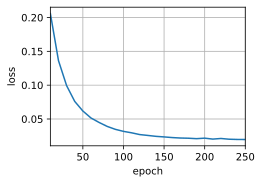

In [ ]:
embed_size, num_hiddens, num_layers, dropout = 32, 32, 2, 0.1
batch_size, num_steps = 64, 10
lr, num_epochs, device = 0.005, 250, d2l.try_gpu()
# 原语言词表，目标语言词表
train_iter, src_vocab, tgt_vocab = d2l.load_data_nmt(batch_size, num_steps)
encoder = d2l.Seq2SeqEncoder(len(src_vocab), embed_size, num_hiddens, num_layers, dropout)
decoder = Seq2SeqAttentionDecoder(len(tgt_vocab), embed_size, num_hiddens, num_layers, dropout)
net = d2l.EncoderDecoder(encoder, decoder)
d2l.train_seq2seq(net, train_iter, lr, num_epochs, tgt_vocab, device)

## 计算BLEU损失

In [11]:
engs = ['go .', "i lost .", 'he\'s calm .', 'i\'m home .']
fras = ['va !', 'j\'ai perdu .', 'il est calme .', 'je suis chez moi .']
for eng, fra in zip(engs, fras):
    translation, dec_attention_weight_seq = d2l.predict_seq2seq(
        net, eng, src_vocab, tgt_vocab, num_steps, device, True)
    print(f'{eng} => {translation}, ',
          f'bleu {d2l.bleu(translation, fra, k=2):.3f}')

go . => va !,  bleu 1.000
i lost . => j'ai perdu .,  bleu 1.000
he's calm . => il est riche .,  bleu 0.658
i'm home . => je suis chez moi .,  bleu 1.000


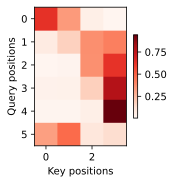

In [ ]:
attention_weights = torch.cat([step[0][0][0] for step in dec_attention_weight_seq], 0).reshape((1, 1, -1, num_steps))
# 加上一个包含序列结束词元
d2l.show_heatmaps(
    attention_weights[:, :, :, :len(engs[-1].split()) + 1].cpu(),
    xlabel='Key positions', ylabel='Query positions')